# 03 · USGS 01403060 – Raritan River water level (2021)

**Utility for the City Brain: high** · Domain: flood · Incident types: `flood`

> A full year of water level every 15 min: the calm baseline FloodNet lacks, six moderate rises and the record flood of Hurricane Ida, all in one series.

| | |
|---|---|
| **Source** | USGS Water Services, instantaneous values, site 01403060 (Raritan River at Bound Brook, NJ), parameter 00065 (gage height) |
| **Licence** | Public domain (US government) |
| **In this repo** | Full file: `data/flood/usgs-raritan/raritan_2021.rdb` |
| **Get it** | https://waterservices.usgs.gov/nwis/iv/?sites=01403060&parameterCd=00065&startDT=2021-01-01&endDT=2021-12-31&format=rdb |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

USGS "RDB" format: tab-separated, comment lines start with `#`, then a header and a column-width line. Columns: agency, site, **datetime** (local, EST/EDT), time zone, **gage height (ft)**, quality code (`A` = approved, `P` = provisional).

In [2]:
w = pd.read_csv(path('flood/usgs-raritan/raritan_2021.rdb'), sep='\t', comment='#', skiprows=[1 + sum(1 for l in open(path('flood/usgs-raritan/raritan_2021.rdb')) if l.startswith('#'))])
w = w.rename(columns={w.columns[4]: 'ft', w.columns[5]: 'quality'})
w['datetime'] = pd.to_datetime(w.datetime); w = w.set_index('datetime')
w['ft'] = pd.to_numeric(w.ft, errors='coerce')
print(f"{len(w):,} readings, {w.index.min()} to {w.index.max()}"); w.head()

34,986 readings, 2021-01-01 00:00:00 to 2021-12-31 23:45:00


,agency_cd,site_no,tz_cd,ft,quality
datetime,,,,,
2021-01-01 00:00:00,USGS,1403060,EST,19.93,A
2021-01-01 00:15:00,USGS,1403060,EST,19.90,A
2021-01-01 00:30:00,USGS,1403060,EST,19.87,A
2021-01-01 00:45:00,USGS,1403060,EST,19.85,A
2021-01-01 01:00:00,USGS,1403060,EST,19.82,A


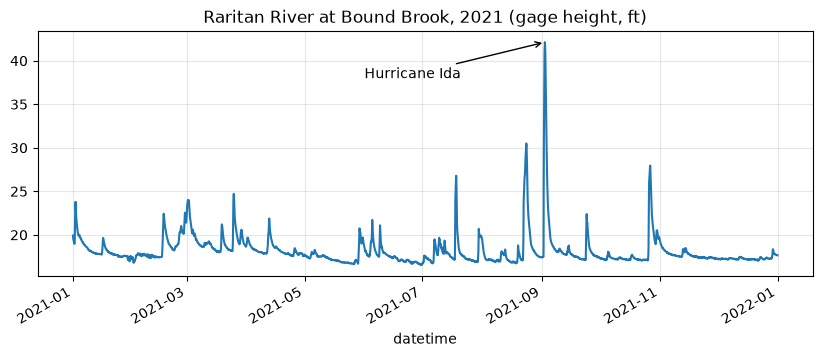

In [3]:
ax = w.ft.plot(title='Raritan River at Bound Brook, 2021 (gage height, ft)')
ax.annotate('Hurricane Ida', xy=(w.ft.idxmax(), w.ft.max()), xytext=(pd.Timestamp('2021-06-01'), 38), arrowprops={'arrowstyle': '->'}); plt.show()

## 2. Calm noise vs a real flood

In [4]:
step = w.ft.diff()
feb = w.loc['2021-02', 'ft']
print('Calm stage deciles (ft):', w.ft.quantile([.1, .5, .9]).round(1).tolist())
print('Normal 15-min change p1 / p50 / p99 (ft):', step.quantile([.01, .5, .99]).round(3).tolist())
print('February standard deviation of the 15-min change (ft):', round(feb.diff().std(), 3))
print('Peak:', w.ft.max(), 'ft at', w.ft.idxmax())
print('Fastest 15-min rise:', round(step.max(), 2), 'ft at', step.idxmax(), f'= {step.max() / step.quantile(.99):.0f} x the normal p99')
print('Hours above 35 ft:', round((w.ft > 35).sum() / 4, 1))

Calm stage deciles (ft): [17.1, 17.7, 19.7]
Normal 15-min change p1 / p50 / p99 (ft): [-0.06, 0.0, 0.08]
February standard deviation of the 15-min change (ft): 0.017
Peak: 42.13 ft at 2021-09-02 12:00:00
Fastest 15-min rise: 1.58 ft at 2021-09-01 20:45:00 = 20 x the normal p99
Hours above 35 ft: 14.0


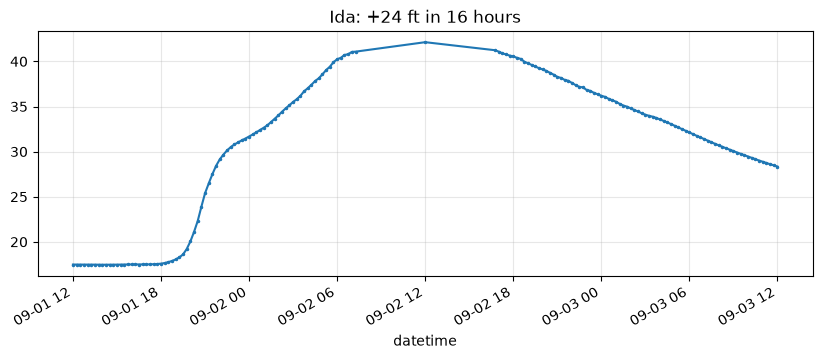

In [5]:
ida = w.loc['2021-09-01 12:00':'2021-09-03 12:00', 'ft']
ida.plot(title='Ida: +24 ft in 16 hours', marker='.', ms=3); plt.show()

In [6]:
# Moderate rises: days when the level rose more than 5 ft above that day's start
daily = w.ft.resample('D').agg(['first', 'max'])
rises = daily[(daily['max'] - daily['first']) > 5]
rises.round(1)

,first,max
datetime,,
2021-08-22,17.1,26.6
2021-09-01,17.4,31.4
2021-09-02,31.7,42.1
2021-10-26,17.4,27.9


## 3. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | Normal noise is tiny (std ≈ 0.02 ft per 15 min), so the 3σ rule fires on Ida within 1–2 readings. Setting: "rising" = step > 5 × normal p99 for 3 readings |
| **Mock** | Scale ft → m and speed up time to make the port's `water_level` sensor: calm months + a real rise |
| **Scenarios** | Calm month = "no incident" test; the moderate rises in the table (e.g. 22 Aug, storm Henri; 26 Oct) = moderate incidents for severity levels; Ida = major flood |
| **Graph** | Same night and county as the Eagle-I outages (notebook 08): a real flood → power chain |

**Limits:** a river gauge, not a street sensor; US units; official flood stages are not in this file.